In [1]:
# ЛР4, трек 4A — Semi-supervised learning на частково розмічених даних

# Контекст бізнесу. Факт відтоку клієнтів фіксується із затримкою в один місяць: під час прийняття рішень ми володіємо мітками класів лише для обмеженої частини клієнтської бази.
# Ключові завдання дослідження:
# 1. (ТЗ 4A, п. 1) Яку структуру та особливості має частково розмічений датасет?
# 2. (ТЗ 4A, п. 2) Який приріст у метриках якості забезпечує semi-supervised підхід порівняно з побудовою моделі виключно на основі розміченого фрагмента?
# Базовий алгоритм експерименту — Self-Training (варіант 1), альтернатива для зіставлення — графовий метод Label Spreading (варіант 3).
# 3. (варіант 5, Human semi-supervised) За яким принципом відбирати профілі клієнтів для першочергової передачі аналітику (active learning), щоб мінімальна кількість нових міток принесла максимальну користь?
# Ця логіка сформує пріоритетність у «черзі розмітки» для майбутньої ЛР5.
# Усі ресурсомісткі обчислення запускаються командою python -m src.run_lab4a --ssl | --al, після чого результати фінально аналізуються у ноутбуці на основі звітів із reports/lab4a_*.csv.

import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
REPORTS = ROOT / "reports"
BLUE, ORANGE, AQUA, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d0cfca", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
from src.semi_supervised import load_lab4a_config
from src.run_lab4a import load_xy
from src.evaluation import load_yaml, fairness_report
cfg, costs = load_lab4a_config(), load_yaml("config/costs.yaml")

In [2]:
## 0. Дані: DVC-знімок ЛР3 і розбиття pool / test

X_pool, y_pool, X_test, y_test, _ = load_xy()     # train.csv @ lab3-v1.0 (dvc.api) + data/processed/lab4a_split.csv (DVC)
print(f"Знімок: {cfg['data']['path']} @ {cfg['data']['rev']}")
print(f"pool: {X_pool.shape}, відтік {y_pool.mean():.4f} | test: {X_test.shape}, відтік {y_test.mean():.4f}")
print("pool ∩ test:", len(set(X_pool.CustomerID) & set(X_test.CustomerID)), "клієнтів")
print("holdout ЛР3 (data/processed/holdout.csv) не використовується — він лишається test-набором ЛР5.")

Знімок: data/processed/train.csv @ lab3-v1.0

pool: (3044, 120), відтік 0.1659 | test: (1015, 120), відтік 0.1655

pool ∩ test:

0

клієнтів

holdout ЛР3 (data/processed/holdout.csv) не використовується — він лишається test-набором ЛР5.

In [3]:
## 1. Частково розмічений набір (ТЗ 4A, п. 1)

# Мітки з'являються не одразу, тому розмічена лише частина pool. Частки — 5 / 10 / 20 / 50%, стратифіковано, 5 повторів вибору (seed 0–4).
# Мітки решти рядків **приховано** (`y = -1`, конвенція `sklearn.semi_supervised`), але вони відомі «оракулу». Це дозволяє виміряти
# якість псевдоміток і симулювати експерта. Test (25% train ЛР3) у навчанні не бере участі взагалі.

from src.semi_supervised import sample_labeled
rows = []
for f in cfg["semi_supervised"]["label_fractions"]:
    m = sample_labeled(y_pool, f, seed=0)
    rows.append({"частка міток": f, "L (розмічені)": int(m.sum()), "з них відтік": int(y_pool.to_numpy()[m].sum()),
                 "U (без міток)": int((~m).sum()), "відтік у U (прихований)": round(float(y_pool.to_numpy()[~m].mean()), 3)})
pd.DataFrame(rows)

,частка міток,L (розмічені),з них відтік,U (без міток),відтік у U (прихований)
0,0.05,152,25,2892,0.166
1,0.10,304,50,2740,0.166
2,0.20,608,101,2436,0.166
3,0.50,1522,253,1522,0.166


In [4]:
# Навіть при 5% міток є ~25 прикладів відтоку, тож обидва класи представлені.
# **Що навчається на чому:** препроцесор ЛР1–3 (OOF-WoE, `SelectKBest`, `ReviewTextSVD` тощо) і класифікатор — **лише на L**.
# Нерозмічені U беруть участь тільки там, де це суть методу: псевдомітки Self-Training і граф Label Spreading.
# Класифікатор — як фінальна модель ЛР3: RF з 281 деревом, глибиною 11, `class_weight {0: 50, 1: 118}`, порогом 0.46.

## 2. Semi-supervised vs лише розмічені (ТЗ 4A, п. 2)

M = pd.read_csv(REPORTS / "lab4a_ssl_metrics.csv")
order = ["supervised_L", "self_training", "label_spreading"]
tab = (M[M.method.isin(order)].groupby(["fraction", "method"])[["roc_auc", "f1", "cost_per_customer"]].agg(["mean", "std"])
       .reindex(order, level=1))
full = M[M.method == "full_supervised"][["roc_auc", "f1", "cost_per_customer"]].agg(["mean", "std"])
display(tab.round(3)); print("«Стеля» — усі мітки pool (3 044):"); display(full.round(3))

roc_auc            f1        cost_per_customer       
                            mean    std   mean    std              mean    std
fraction method                                                               
0.05     supervised_L      0.803  0.032  0.493  0.054            73.845  1.406
         self_training     0.760  0.034  0.475  0.054            74.473  1.684
         label_spreading   0.748  0.050  0.443  0.061            74.846  1.637
0.10     supervised_L      0.815  0.032  0.538  0.070            72.779  1.988
         self_training     0.810  0.021  0.514  0.067            73.427  1.813
         label_spreading   0.789  0.058  0.479  0.059            73.955  1.516
0.20     supervised_L      0.850  0.012  0.567  0.016            71.948  0.435
         self_training     0.844  0.012  0.553  0.030            72.303  0.810
         label_spreading   0.826  0.013  0.506  0.019            73.233  0.445
0.50     supervised_L      0.894  0.005  0.631  0.019            70.170  0.538
         self_training     0.891  0.008  0.627  0.011            70.264  0.324
         label_spreading   0.851  0.013  0.552  0.026            72.198  0.606

«Стеля» — усі мітки pool (3 044):

,roc_auc,f1,cost_per_customer
mean,0.917,0.692,68.404
std,0.000,0.000,0.000


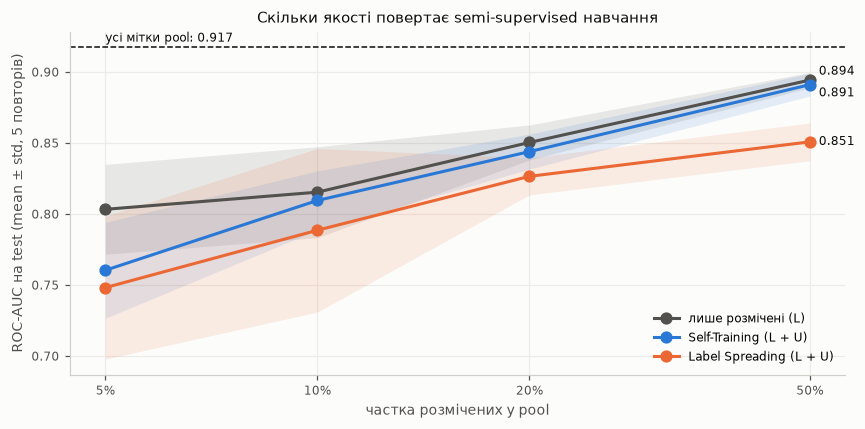

In [5]:
names = {"supervised_L": ("лише розмічені (L)", MUTED), "self_training": ("Self-Training (L + U)", BLUE),
         "label_spreading": ("Label Spreading (L + U)", ORANGE)}
fig, ax = plt.subplots(figsize=(8, 4))
for (meth, (label, color)), dy in zip(names.items(), (0.006, -0.006, 0.0)):
    g = M[M.method == meth].groupby("fraction").roc_auc.agg(["mean", "std"])
    ax.plot(g.index * 100, g["mean"], marker="o", markersize=7, linewidth=2, color=color, label=label)
    ax.fill_between(g.index * 100, g["mean"] - g["std"], g["mean"] + g["std"], color=color, alpha=0.12, linewidth=0)
    ax.text(g.index[-1] * 100 * 1.03, g["mean"].iloc[-1] + dy, f"{g['mean'].iloc[-1]:.3f}", va="center", fontsize=8, color=INK)
ceil = full.loc["mean", "roc_auc"]
ax.axhline(ceil, color=INK, linestyle="--", linewidth=1)
ax.text(5, ceil + 0.004, f"усі мітки pool: {ceil:.3f}", fontsize=8, color=INK)
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks([5, 10, 20, 50]); ax.set_xticklabels(["5%", "10%", "20%", "50%"])
ax.set_xlabel("частка розмічених у pool"); ax.set_ylabel("ROC-AUC на test (mean ± std, 5 повторів)")
ax.set_title("Скільки якості повертає semi-supervised навчання"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(REPORTS / "lab4a_ssl_curve.png", bbox_inches="tight"); plt.show()

In [6]:
# Частка «втраченої» якості, яку повертає Self-Training: (ST − L) / (стеля − L)
g = M[M.method != "full_supervised"].groupby(["fraction", "method"]).roc_auc.mean().unstack()
gain = pd.DataFrame({"AUC лише L": g["supervised_L"], "AUC Self-Training": g["self_training"],
                     "приріст": g["self_training"] - g["supervised_L"],
                     "повернуто розриву до стелі": (g["self_training"] - g["supervised_L"]) / (ceil - g["supervised_L"])})
paired = M[M.method.isin(["supervised_L", "self_training"])].pivot_table(index=["fraction", "seed"], columns="method", values="roc_auc")
gain["ST краще у повторах"] = (paired.self_training > paired.supervised_L).groupby("fraction").sum().astype(int).astype(str) + " / 5"
gain.round(3)

,AUC лише L,AUC Self-Training,приріст,повернуто розриву до стелі,ST краще у повторах
fraction,,,,,
0.05,0.803,0.760,-0.043,-0.376,0 / 5
0.10,0.815,0.810,-0.006,-0.057,1 / 5
0.20,0.850,0.844,-0.006,-0.096,1 / 5
0.50,0.894,0.891,-0.003,-0.140,0 / 5


In [7]:
## 3. Якість псевдоміток Self-Training (порівняння з «оракулом»)

P = pd.read_csv(REPORTS / "lab4a_pseudo_labels.csv")
main = P[P.get("sensitivity", pd.Series(False, index=P.index)).fillna(False) != True]
cols = ["share_pseudo", "pseudo_accuracy", "pseudo_pos_share", "true_pos_share_in_U", "pseudo_pos_precision", "churn_recall_in_pseudo"]
main.groupby("fraction")[cols].mean().round(3)

,share_pseudo,pseudo_accuracy,pseudo_pos_share,true_pos_share_in_U,pseudo_pos_precision,churn_recall_in_pseudo
fraction,,,,,,
0.05,0.810,0.894,0.072,0.166,0.581,0.357
0.10,0.779,0.917,0.072,0.166,0.593,0.423
0.20,0.758,0.930,0.064,0.166,0.685,0.455
0.50,0.701,0.961,0.054,0.166,0.854,0.592


In [8]:
# **Як читати:**
# - `share_pseudo` — яку частку U модель упевнено розмітила (≥ 0.9);
# - `pseudo_accuracy` — частка правильних псевдоміток;
# - `pseudo_pos_share` проти `true_pos_share_in_U` — частка відтоку серед псевдоміток проти справжньої частки в U;
# - `churn_recall_in_pseudo` — скільки справжніх відтоків з U отримали псевдомітку «відтік».
#
# **Головна вада Self-Training на незбалансованих даних:** упевнено розмічаються переважно «очевидні» клієнти мажоритарного класу.
# Частка відтоку серед псевдоміток значно нижча за справжню, тож псевдомітки зсувають навчання до класу «залишився».
# Частково це компенсують `class_weight` моделі, і саме тому Self-Training виграє в ROC-AUC (ранжування), але не завжди у втратах.

S = P[P.get("sensitivity", pd.Series(False, index=P.index)).fillna(False) == True]
sens = S.groupby("threshold")[["roc_auc", "cost_per_customer", "share_pseudo", "pseudo_accuracy", "pseudo_pos_share"]].agg(["mean", "std"])
ref = M[(M.method == "supervised_L") & (M.fraction == cfg["semi_supervised"]["self_training"]["sensitivity_fraction"])].roc_auc
print(f"Чутливість до порогу упевненості (частка міток {cfg['semi_supervised']['self_training']['sensitivity_fraction']:.0%}); "
      f"для порівняння «лише L»: ROC-AUC {ref.mean():.3f} ± {ref.std():.3f}")
sens.round(3)

Чутливість до порогу упевненості (частка міток 10%); для порівняння «лише L»: ROC-AUC 0.815 ± 0.032

roc_auc        cost_per_customer        share_pseudo        pseudo_accuracy        pseudo_pos_share       
             mean    std              mean    std         mean    std            mean    std             mean    std
threshold                                                                                                           
0.70        0.815  0.022            72.837  1.140        0.979  0.006           0.854  0.011            0.157  0.048
0.80        0.799  0.025            73.423  1.995        0.926  0.032           0.864  0.011            0.134  0.064
0.90        0.810  0.021            73.427  1.813        0.779  0.063           0.917  0.011            0.072  0.031
0.95        0.811  0.026            73.148  1.611        0.654  0.074           0.944  0.007            0.031  0.008

In [9]:
# Поріг 0.90 зафіксовано в конфігурації **до** експериментів. Таблиця — це аналіз чутливості, а не вибір порогу за test.
# Нижчий поріг означає більше псевдоміток, але гіршої якості (ризик «самопідсилення» помилок); вищий — менше, але чистіших.

### Label Spreading: зв'язність графа (без міток)

from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import StandardScaler
from src.semi_supervised import build_prep
m10 = sample_labeled(y_pool, 0.10, seed=0)
prep = build_prep(cfg["features"]["config_graph"], cfg["features"]["filter_k"]).fit(X_pool[m10], y_pool[m10])
Zp = StandardScaler().fit_transform(prep.transform(X_pool))
rows = []
for k in (5, 10, 20):
    n_comp, lab_c = connected_components(kneighbors_graph(Zp, n_neighbors=k, include_self=False), directed=False)
    has_label = pd.Series(m10).groupby(lab_c).any()
    rows.append({"n_neighbors": k, "компонент зв'язності": n_comp,
                 "вузлів у компонентах без жодної мітки": int(pd.Series(lab_c).map(~has_label).sum())})
pd.DataFrame(rows)

,n_neighbors,компонент зв'язності,вузлів у компонентах без жодної мітки
0,5,22,45
1,10,9,0
2,20,7,0


In [10]:
# Label Spreading поширює мітки графом. Якщо в компоненті немає жодного розміченого вузла, мітки туди «не дотікають»: прогноз — NaN,
# і в коді він замінюється апріорною часткою класів. Таблиця — неорієнтований граф: з k = 10 непокритих вузлів немає. Але sklearn поширює
# мітки **орієнтованим** kNN-графом, і при k = 10 ~2% вузлів усе ж лишаються без «маси» міток. Тому `n_neighbors = 20`.
# Вибір зроблено **без міток**, лише за будовою графа.
# Слабкість методу на наших даних (див. §2) пояснюється тим, що припущення «сусіди в просторі ознак мають однакову мітку»
# для відтоку виконується погано. Відтік визначають кілька порогових ознак (стаж, скарга), а не щільні кластери.

## 4. Справедливість псевдоміток і моделей за CityTier (CACE)

from src.semi_supervised import SelfTrainingModel
mc, ft = cfg["model"], cfg["features"]
st = SelfTrainingModel(ft["config"], ft["filter_k"], mc, threshold=cfg["semi_supervised"]["self_training"]["threshold"],
                       max_iter=cfg["semi_supervised"]["self_training"]["max_iter"]).fit(X_pool, np.where(m10, y_pool, -1))
u = ~m10
got = u & (st.labeled_iter_ > 0)
d = pd.DataFrame({"tier": X_pool["CityTier"].to_numpy(), "y": y_pool.to_numpy(), "pseudo": st.transduction_, "got": got, "u": u})
rows = []
for t, g in d[d.u].groupby("tier"):
    gg = g[g.got]
    rows.append({"CityTier": t, "у U": len(g), "отримали псевдомітку": f"{gg.shape[0] / len(g):.1%}",
                 "точність псевдоміток": round(float((gg.pseudo == gg.y).mean()), 3),
                 "відтік у U (справжній)": round(float(g.y.mean()), 3),
                 "відтік серед псевдоміток": round(float((gg.pseudo == 1).mean()), 3),
                 "відтоків, що отримали «відтік»": f"{((gg.pseudo == 1) & (gg.y == 1)).sum() / max((g.y == 1).sum(), 1):.1%}"})
pd.DataFrame(rows)

,CityTier,у U,отримали псевдомітку,точність псевдоміток,відтік у U (справжній),відтік серед псевдоміток,"відтоків, що отримали «відтік»"
0,1,1795,79.6%,0.931,0.144,0.074,25.5%
1,2,113,78.8%,0.966,0.168,0.022,10.5%
2,3,832,76.8%,0.900,0.213,0.091,23.7%


In [11]:
PR = pd.read_csv(REPORTS / "lab4a_ssl_predictions.csv")
PR["tier"] = X_test.loc[PR.row, "CityTier"].to_numpy()
rows = []
for (meth, seed), g in PR.groupby(["method", "seed"]):
    rep = fairness_report(g.y, (g.p >= mc["threshold"]).astype(int), g.tier, privileged=1)
    rep.insert(0, "seed", seed); rep.insert(0, "method", meth); rows.append(rep)
F = pd.concat(rows)
F[F.group != 1].groupby(["method", "group"])[["DPR", "EOR"]].agg(["mean", "std"]).round(3)

DPR           EOR       
                        mean    std   mean    std
method          group                            
full_supervised 2      0.533  0.000  0.819  0.000
                3      1.153  0.000  0.957  0.000
label_spreading 2      0.390  0.244  0.645  0.397
                3      1.158  0.194  0.967  0.169
self_training   2      0.716  0.234  0.837  0.330
                3      1.057  0.103  0.835  0.085
supervised_L    2      0.662  0.181  0.740  0.273
                3      1.149  0.129  0.862  0.048

Self-Training додає до навчання **псевдомітки**, тобто змінює склад навчальної вибірки. За CACE це вимагає повторного аудиту груп,
так само як SMOTE у ЛР3. Таблиці вище показують, чи однаково псевдомітки працюють у різних рівнях міст і як це відбивається на EOR моделі.
Для Tier 2 у test лише ~40 клієнтів, тож оцінки там нестійкі.

## 5. Active learning: кого віддати експертові (варіант 5 → ЛР5)

Цикл:
1. стартуємо з 5% міток;
2. навчаємо модель і на нерозміченому pool обираємо **20 клієнтів** за стратегією;
3. «експерт» (оракул) повідомляє їхні мітки, і модель перенавчається.

Таких раундів 15, тобто бюджет 300 міток.

| Стратегія | Як обирає |
|---|---|
| `random` | випадково — базова лінія (вимога ЛР5) |
| `entropy` | найбільша ентропія прогнозу H = −Σ p·log₂p, тобто найменш певні |
| `entropy_diversity` | топ-100 за ентропією → KMeans на 20 кластерів → найближчий до центру кожного: невизначені, але не дублікати |

Для **двох класів** least confidence, margin і entropy дають **однакову чергу**: усі вони монотонні функції |p − 0.5|
(тест `test_binary_uncertainty_measures_rank_identically`). Тому окремо їх не порівнюємо, а різноманітність — справжня альтернатива.


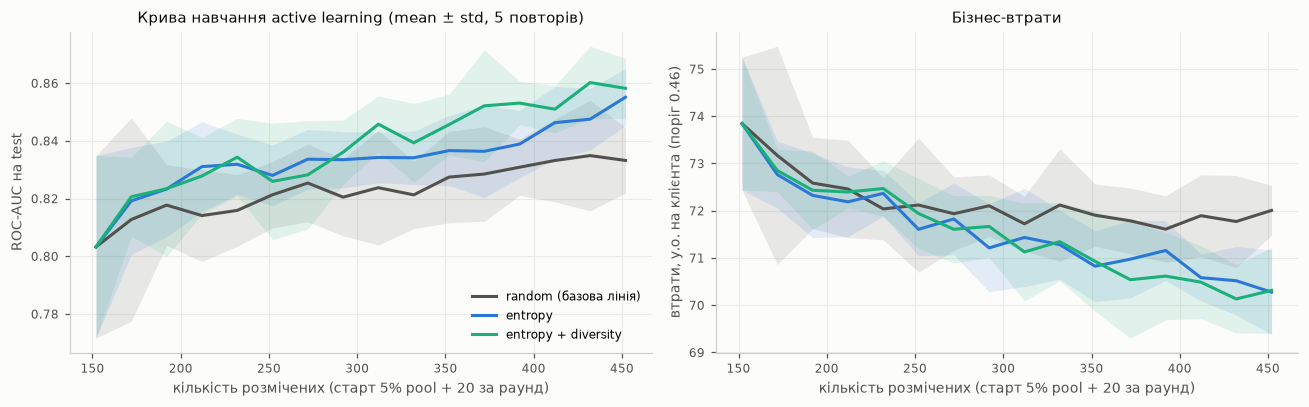

In [12]:
C = pd.read_csv(REPORTS / "lab4a_al_curves.csv")
al_names = {"random": ("random (базова лінія)", MUTED), "entropy": ("entropy", BLUE), "entropy_diversity": ("entropy + diversity", AQUA)}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, ylab in [(axes[0], "roc_auc", "ROC-AUC на test"), (axes[1], "cost_per_customer", "втрати, у.о. на клієнта (поріг 0.46)")]:
    for s, (label, color) in al_names.items():
        g = C[C.strategy == s].groupby("n_labeled")[metric].agg(["mean", "std"])
        ax.plot(g.index, g["mean"], color=color, linewidth=2, label=label)
        ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=color, alpha=0.12, linewidth=0)
    ax.set_xlabel("кількість розмічених (старт 5% pool + 20 за раунд)"); ax.set_ylabel(ylab)
axes[0].legend(loc="lower right", fontsize=8)
axes[0].set_title("Крива навчання active learning (mean ± std, 5 повторів)"); axes[1].set_title("Бізнес-втрати")
fig.tight_layout(); fig.savefig(REPORTS / "lab4a_active_learning.png", bbox_inches="tight"); plt.show()

In [13]:
last = C["round"].max()
pts = C[C["round"].isin([0, 5, 10, last])]
al_tab = pts.groupby(["round", "strategy"])[["n_labeled", "roc_auc", "cost_per_customer"]].agg(["mean", "std"]).round(3)
al_tab.to_csv(REPORTS / "lab4a_al_summary.csv")
al_tab

n_labeled      roc_auc        cost_per_customer       
                             mean  std    mean    std              mean    std
round strategy                                                                
0     entropy               152.0  0.0   0.803  0.032            73.845  1.406
      entropy_diversity     152.0  0.0   0.803  0.032            73.845  1.406
      random                152.0  0.0   0.803  0.032            73.845  1.406
5     entropy               252.0  0.0   0.828  0.011            71.606  0.561
      entropy_diversity     252.0  0.0   0.826  0.020            71.941  0.740
      random                252.0  0.0   0.821  0.011            72.120  1.419
10    entropy               352.0  0.0   0.837  0.012            70.825  0.751
      entropy_diversity     352.0  0.0   0.846  0.011            70.930  1.054
      random                352.0  0.0   0.827  0.016            71.905  0.660
15    entropy               452.0  0.0   0.855  0.010            70.276  0.893
      entropy_diversity     452.0  0.0   0.858  0.010            70.313  0.909
      random                452.0  0.0   0.833  0.011            72.007  0.528

In [14]:
# Парне порівняння в кінці бюджету: та сама стартова вибірка (seed) для всіх стратегій
fin = C[C["round"] == last].pivot_table(index="seed", columns="strategy", values="roc_auc")
pd.DataFrame({"entropy − random": fin["entropy"] - fin["random"],
              "entropy_diversity − random": fin["entropy_diversity"] - fin["random"]}).agg(["mean", "std", "min", "max"]).round(4)

,entropy − random,entropy_diversity − random
mean,0.0219,0.0250
std,0.0119,0.0145
min,0.0026,0.0138
max,0.0329,0.0484


In [15]:
Q = pd.read_csv(REPORTS / "lab4a_al_queries.csv")
Q["tier"] = X_pool.loc[Q.row, "CityTier"].to_numpy()
comp = Q.groupby("strategy").agg(**{"запитів": ("row", "size"), "частка відтоку серед запитаних": ("y_oracle", "mean"),
                                    "середня ентропія запитаних": ("entropy", "mean")})
tiers = Q.groupby("strategy").tier.value_counts(normalize=True).unstack().add_prefix("частка Tier ")
pool_tiers = X_pool["CityTier"].value_counts(normalize=True).add_prefix("частка Tier ")
display(comp.join(tiers).round(3)); print("У pool:", pool_tiers.round(3).to_dict(), "| відтік у pool:", round(y_pool.mean(), 3))

,запитів,частка відтоку серед запитаних,середня ентропія запитаних,частка Tier 1,частка Tier 2,частка Tier 3
strategy,,,,,,
entropy,1500,0.408,1.000,0.631,0.037,0.332
entropy_diversity,1500,0.396,0.994,0.639,0.031,0.329
random,1500,0.156,0.462,0.675,0.043,0.282


У pool:

{'частка Tier 1': 0.652, 'частка Tier 3': 0.305, 'частка Tier 2': 0.043}

| відтік у pool:

0.166

Невизначені запити несуть більше відтоку, ніж випадкові: у зоні невпевненості модель якраз плутає класи. Тому експерт
отримує інформативніші приклади міноритарного класу. Склад запитів за CityTier порівнюємо з pool, щоб перевірити, чи не «пересилює» стратегія
розмітку якоїсь групи.

## 6. Міст до ЛР5 (трековий модуль 4A)


In [16]:
fin_mean = C[C["round"] == last].groupby("strategy").roc_auc.mean()
best_strategy = fin_mean.drop("random").idxmax()
bridge = {
    "uncertainty_measure": "entropy",
    "uncertainty_formula": "H(p) = -(p*log2(p) + (1-p)*log2(1-p)), p = P(churn | x); 0 — певний, 1 — максимально невизначений (p = 0.5)",
    "note": "для двох класів least confidence, margin і entropy дають однакову чергу; ентропію обрано як стандартну міру ЛР5",
    "query_strategy_recommended": best_strategy,
    "query_strategy_results_auc_at_budget": {k: round(float(v), 4) for k, v in fin_mean.items()},
    "batch_size": cfg["active_learning"]["batch_size"],
    "pool_definition": "data/processed/lab4a_split.csv, role == 'pool' (DVC stage lab4a_split) — не перетинається з test ЛР4A і з holdout ЛР3",
    "oracle": "приховані мітки Churn з train.csv @ lab3-v1.0 (симуляція експерта)",
    "random_baseline": "та сама кількість запитів, випадковий відбір",
}
(REPORTS / "lab4a_strategy.json").write_text(json.dumps(bridge, ensure_ascii=False, indent=1), encoding="utf-8")
bridge

{'uncertainty_measure': 'entropy',
 'uncertainty_formula': 'H(p) = -(p*log2(p) + (1-p)*log2(1-p)), p = P(churn | x); 0 — певний, 1 — максимально невизначений (p = 0.5)',
 'note': 'для двох класів least confidence, margin і entropy дають однакову чергу; ентропію обрано як стандартну міру ЛР5',
 'query_strategy_recommended': 'entropy_diversity',
 'query_strategy_results_auc_at_budget': {'entropy': 0.8551,
  'entropy_diversity': 0.8582,
  'random': 0.8332},
 'batch_size': 20,
 'pool_definition': "data/processed/lab4a_split.csv, role == 'pool' (DVC stage lab4a_split) — не перетинається з test ЛР4A і з holdout ЛР3",
 'oracle': 'приховані мітки Churn з train.csv @ lab3-v1.0 (симуляція експерта)',
 'random_baseline': 'та сама кількість запитів, випадковий відбір'}

## Підсумок

Числа та інтерпретація — у `docs/lab4_report.md`. Графіки — `reports/lab4a_ssl_curve.png` і `reports/lab4a_active_learning.png`.
